<a href="https://colab.research.google.com/github/SyedAliAsghar-512/TextOriginMiner/blob/main/notebooks/03_features_attribution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS-311 · P04 · M1: Style features + hypothesis test (Mining lead)
Style features on cleaned text, human vs AI and per generator, plots, and a Mann-Whitney U test. Runs on its own, top to bottom.
**Save to GitHub:** File → Save a copy in GitHub → `notebooks/03_features_attribution.ipynb`

In [1]:
!pip install -q datasets textstat
import string
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import textstat
from scipy.stats import mannwhitneyu

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.1/177.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 21.4 MB/s eta 0:00:00


In [2]:
# ---- Load + clean the data (this same cell is in every team notebook, so everyone gets identical data) ----
import re, html, unicodedata
import pandas as pd
from datasets import load_dataset

ERROR_PREFIX = "Error: Error communicating with OpenAI"   # failed GPT-4o API calls, not real articles

# Website boilerplate lines found in human texts but (almost) never in AI texts (from the Data lead's report).
# Removed only when a WHOLE line matches, so real sentences are never cut.
NAV_LINES = {
    "The New York Times", "Site Navigation", "Site Search Navigation", "Site Mobile Navigation",
    "Slideshow controls", "Recent Episodes", "What's Next", "transcript", "Covid-19Guidance", "Archive",
    "Supported by", "United States", "Credits", "Data", "Nursing Homes", "Vaccines", "Treatments",
    "Global Vaccinations", "Deaths Above Normal", "Colleges and Universities", "Your County’s Risk",
    "Hospitals Near You", "Your Places",
}
# Template lines in AI texts such as "By [Your Name]", "Published: [Date]", "By Your Name"
PLACEHOLDER_LINE = re.compile(
    r"^\s*(?:by|written by|published|date|author)\b[^\n]{0,30}\[[^\]\n]{1,40}\][^\n]{0,20}$|^\s*by your name\s*$", re.I)

def clean_text(text):
    text = unicodedata.normalize("NFKC", html.unescape(text))
    text = re.sub(r"<[^<>\n]{1,50}>", " ", text)                    # HTML tags
    text = re.sub(r"\*\*|__", "", text)                              # markdown bold
    text = re.sub(r"(?m)^[ \t]*#{1,6}[ \t]*", "", text)              # markdown headings
    lines = [l for l in text.split("\n")
             if l.strip() not in NAV_LINES and not PLACEHOLDER_LINE.match(l)]
    text = re.sub(r"^\s*(?:Comments\b|Title:)\s*", "", "\n".join(lines))   # leading "Comments" / "Title:"
    text = re.sub(r"[ \t]+", " ", text)
    return re.sub(r"\n\s*\n+", "\n\n", text).strip()

def load_clean(min_words=50):
    ds = load_dataset("Rajarshi-Roy-research/Defactify_Text_Dataset")
    df = pd.concat([ds[s].to_pandas().assign(split=s) for s in ds.keys()], ignore_index=True)
    df.columns = [c.lower() for c in df.columns]                     # text, label_a, label_b, split
    report = {"rows_before": len(df)}

    df["text"] = df["text"].fillna("")
    empty = df["text"].str.strip() == ""
    report["missing_or_empty"] = int(empty.sum()); df = df[~empty]

    error = df["text"].str.lstrip().str.startswith(ERROR_PREFIX)
    report["api_error_texts"] = int(error.sum()); df = df[~error].copy()

    df["text"] = df["text"].map(clean_text)
    df["n_words"] = df["text"].str.split().str.len()
    short = df["n_words"] < min_words
    report[f"under_{min_words}_words"] = int(short.sum()); df = df[~short].copy()

    df["key"] = df["text"].str.lower().str.split().str.join(" ")
    n = len(df); df = df.drop_duplicates(["split", "key"])
    report["duplicates_within_split"] = n - len(df)
    in_eval = set(df.loc[df["split"] != "train", "key"])
    leak = (df["split"] == "train") & df["key"].isin(in_eval)
    report["train_copies_of_eval_texts"] = int(leak.sum())
    df = df[~leak].drop(columns="key").reset_index(drop=True)

    report["rows_after"] = len(df)
    for k, v in report.items():
        print(f"{k:>28}: {v:,}")
    return df, report

In [3]:
df, report = load_clean()
train = df[df["split"] == "train"]
print(train["label_b"].value_counts())

README.md:   0%|          | 0.00/2.69k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 86.2MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/51247 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10983 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10963 [00:00<?, ? examples/s]

                 rows_before: 73,193
            missing_or_empty: 85
             api_error_texts: 343
              under_50_words: 1,079
     duplicates_within_split: 62
  train_copies_of_eval_texts: 26
                  rows_after: 71,598
label_b
Qwen-2-72B     7310
Gemma-2-9B     7306
Mistral-7B     7304
Yi-Large       7295
Llama-8B       7282
GPT-4o         7032
Human_Story    6492
Name: count, dtype: int64


## 2. Sample (documented)
Style features on ~50k long articles are slow on Colab, so we use a **stratified sample of 1,500 training texts per source** with a fixed seed. Mention this in the report.

In [4]:
N_PER_SOURCE = min(1500, train["label_b"].value_counts().min())
sample = train.groupby("label_b").sample(n=N_PER_SOURCE, random_state=SEED).reset_index(drop=True)
print(sample["label_b"].value_counts())

label_b
GPT-4o         1500
Gemma-2-9B     1500
Human_Story    1500
Llama-8B       1500
Mistral-7B     1500
Qwen-2-72B     1500
Yi-Large       1500
Name: count, dtype: int64


## 3. Style features per text
- **word_count**: number of words
- **avg_sentence_len**: words per sentence
- **ttr_200**: type-token ratio on the first 200 words. Plain TTR drops as texts get longer, so this keeps the comparison fair.
- **punct_per_100_words**: punctuation marks per 100 words
- **flesch_reading_ease**: readability (higher = easier to read)

In [5]:
WORD = re.compile(r"[A-Za-z']+")
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")
PUNCT = set(string.punctuation)

def style_features(text):
    words = WORD.findall(text)
    n_words = len(words)
    sentences = [s for s in SENT_SPLIT.split(text.strip()) if WORD.search(s)]
    first_200 = [w.lower() for w in words[:200]]
    return {
        "word_count": n_words,
        "avg_sentence_len": n_words / max(len(sentences), 1),
        "ttr_200": len(set(first_200)) / max(len(first_200), 1),
        "punct_per_100_words": 100 * sum(ch in PUNCT for ch in text) / max(n_words, 1),
        "flesch_reading_ease": textstat.flesch_reading_ease(text),
    }

feats = pd.DataFrame([style_features(t) for t in sample["text"]])
data = pd.concat([sample[["label_a", "label_b"]], feats], axis=1)
data["group"] = data["label_a"].map({0: "Human", 1: "AI"})

FEATURES = ["word_count", "avg_sentence_len", "ttr_200", "punct_per_100_words", "flesch_reading_ease"]
data.head()

,label_a,label_b,word_count,avg_sentence_len,ttr_200,punct_per_100_words,flesch_reading_ease,group
0,1,GPT-4o,473,21.500000,0.600,14.164905,36.023494,AI
1,1,GPT-4o,657,28.565217,0.645,12.480974,27.915906,AI
2,1,GPT-4o,675,18.243243,0.575,16.444444,31.420345,AI
3,1,GPT-4o,535,24.318182,0.715,15.327103,32.745425,AI
4,1,GPT-4o,546,21.840000,0.610,16.483516,29.182923,AI


## 4. Medians: human vs AI, and per source

In [6]:
HUMAN = "Human_Story"
order = [HUMAN] + sorted(x for x in data["label_b"].unique() if x != HUMAN)

by_group = data.groupby("group")[FEATURES].median().round(2)
by_source = data.groupby("label_b")[FEATURES].median().round(2).reindex(order)
display(by_group)
display(by_source)

,word_count,avg_sentence_len,ttr_200,punct_per_100_words,flesch_reading_ease
group,,,,,
AI,430.0,23.19,0.61,15.90,37.05
Human,394.0,20.66,0.61,15.42,47.27


,word_count,avg_sentence_len,ttr_200,punct_per_100_words,flesch_reading_ease
label_b,,,,,
Human_Story,394.0,20.66,0.61,15.42,47.27
GPT-4o,583.5,22.33,0.64,15.41,27.38
Gemma-2-9B,340.0,21.89,0.64,19.42,35.51
Llama-8B,452.0,25.11,0.60,17.78,41.64
Mistral-7B,383.0,23.27,0.60,15.44,38.05
Qwen-2-72B,376.0,22.90,0.57,14.51,44.93
Yi-Large,486.0,23.98,0.60,13.61,34.04


## 5. Plots

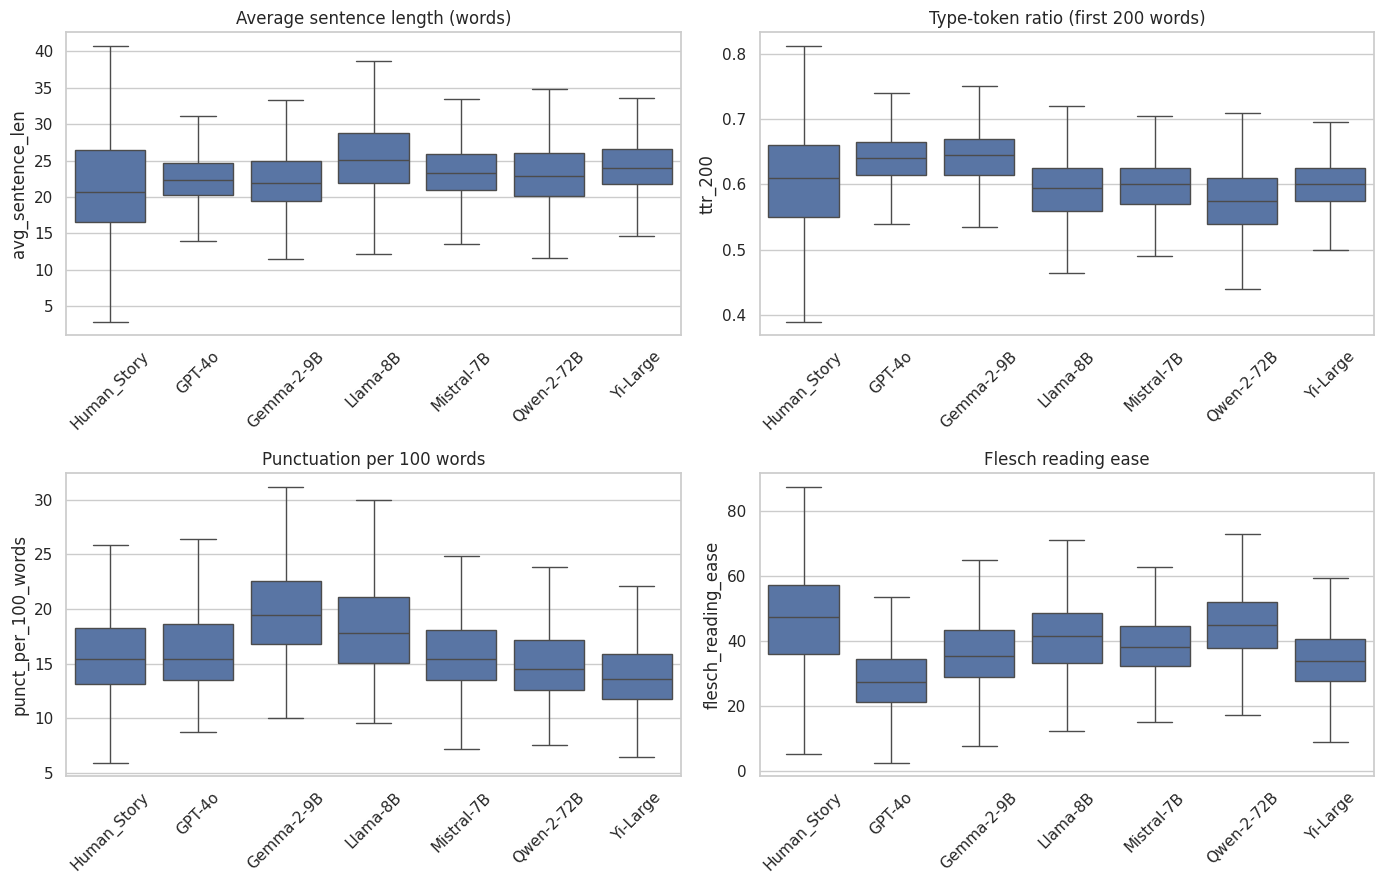

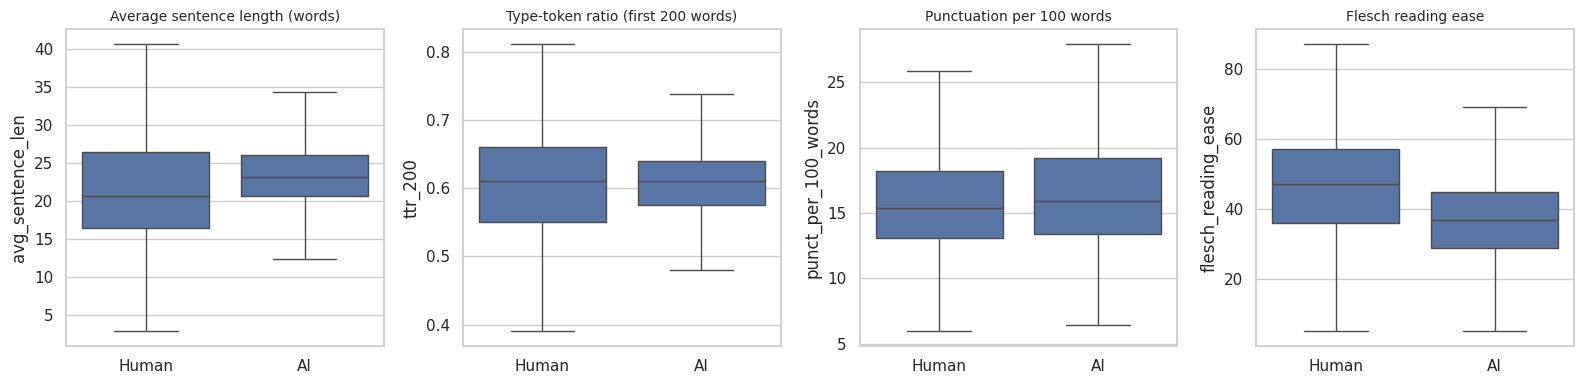

In [7]:
titles = {"avg_sentence_len": "Average sentence length (words)", "ttr_200": "Type-token ratio (first 200 words)",
          "punct_per_100_words": "Punctuation per 100 words", "flesch_reading_ease": "Flesch reading ease"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, title) in zip(axes.ravel(), titles.items()):
    sns.boxplot(data=data, x="label_b", y=col, order=order, showfliers=False, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (col, title) in zip(axes, titles.items()):
    sns.boxplot(data=data, x="group", y=col, order=["Human", "AI"], showfliers=False, ax=ax)
    ax.set_title(title, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Hypothesis test: Mann-Whitney U
**H0:** human and AI texts have the same distribution of average sentence length. **H1:** they differ (two-sided).
We use Mann-Whitney U rather than a t-test because it does not assume normal data.
**Effect size:** U ÷ (n_human × n_AI) = the chance a random human text has longer sentences than a random AI text (0.5 = no difference).

In [8]:
human = data.loc[data["group"] == "Human", "avg_sentence_len"]
ai    = data.loc[data["group"] == "AI",    "avg_sentence_len"]
u, p = mannwhitneyu(human, ai, alternative="two-sided")

print(f"Median sentence length  Human: {human.median():.1f}   AI: {ai.median():.1f}")
print(f"Mann-Whitney U = {u:.0f},  p = {p:.3g},  P(human longer than AI) = {u / (len(human) * len(ai)):.2f}")
print("Reject H0 at 0.05" if p < 0.05 else "Cannot reject H0 at 0.05")

Median sentence length  Human: 20.7   AI: 23.2
Mann-Whitney U = 5404424,  p = 3.36e-35,  P(human longer than AI) = 0.40
Reject H0 at 0.05


### Same test for every feature (5 tests → Bonferroni threshold 0.05 / 5 = 0.01)

In [9]:
rows = []
for f in FEATURES:
    h, a = data.loc[data["group"] == "Human", f], data.loc[data["group"] == "AI", f]
    u, p = mannwhitneyu(h, a, alternative="two-sided")
    rows.append({"feature": f, "human_median": h.median(), "ai_median": a.median(), "p_value": p,
                 "P(human > AI)": u / (len(h) * len(a)), "significant (p < 0.01)": p < 0.05 / len(FEATURES)})
pd.DataFrame(rows).round(4)

,feature,human_median,ai_median,p_value,P(human > AI),significant (p < 0.01)
0,word_count,394.0000,430.0000,0.1136,0.4873,False
1,avg_sentence_len,20.6617,23.1875,0.0000,0.4003,True
2,ttr_200,0.6100,0.6100,0.5308,0.5050,False
3,punct_per_100_words,15.4197,15.9000,0.0000,0.4633,True
4,flesch_reading_ease,47.2734,37.0532,0.0000,0.6816,True


## Findings (fill in after running)
- Sample: ___ cleaned training texts per source, seed 42, because ___.
- Human median sentence length ___ vs AI ___; Mann-Whitney p = ___, P(human longer) = ___ → ___.
- Biggest human-vs-AI differences: ___ and ___. TTR: ___ vs ___.
- Llama-8B: ___ words per sentence, far from the other sources (see the Data lead's punctuation check).
- Most human-like generator by style: ___; least human-like: ___.